##  Diplomado en Ciencia de Datos

<h1 align = 'center'> Solución: seguimiento de experimentos con MLflow </h1>

Soluciones de los ejercicios de `13_MLflow_Tracking.ipynb`. El cuaderno es autocontenido: primero repite la configuración del cuaderno 13 y luego resuelve cada ejercicio. Las observaciones numéricas corresponden a una ejecución con las semillas indicadas; los decimales pueden cambiar, las conclusiones no.

<h2 style="color: #007ACC;">Configuración (del cuaderno 13)</h2>

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn imbalanced-learn mlflow

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import sklearn
import mlflow

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, TunedThresholdClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, recall_score, precision_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score,
                             PrecisionRecallDisplay, RocCurveDisplay, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek

mlflow.set_tracking_uri('sqlite:///mlflow_solucion.db')

def generar_datos(n, prev, sep=1.0, semilla=0):
    return make_classification(n_samples=n, n_features=10, n_informative=4, n_redundant=2,
                               n_clusters_per_class=2, weights=[1 - prev, prev], flip_y=0,
                               class_sep=sep, random_state=semilla)

def evaluar(modelo, X_te, y_te):
    pred = modelo.predict(X_te)
    puntaje = modelo.predict_proba(X_te)[:, 1] if hasattr(modelo, 'predict_proba') else modelo.decision_function(X_te)
    return {'accuracy': accuracy_score(y_te, pred), 'recall': recall_score(y_te, pred),
            'precision': precision_score(y_te, pred, zero_division=0), 'f1': f1_score(y_te, pred, zero_division=0),
            'bal_acc': balanced_accuracy_score(y_te, pred), 'mcc': matthews_corrcoef(y_te, pred),
            'roc_auc': roc_auc_score(y_te, puntaje), 'pr_auc': average_precision_score(y_te, puntaje)}

def construir(tecnica, semilla=0):
    lr = lambda **kw: LogisticRegression(max_iter=1000, **kw)
    escala = ('escala', StandardScaler())
    if tecnica == 'Sin corrección':           return ImbPipeline([escala, ('m', lr())])
    if tecnica == 'class_weight=balanced':    return ImbPipeline([escala, ('m', lr(class_weight='balanced'))])
    if tecnica == 'Sub-muestreo aleatorio':   return ImbPipeline([escala, ('r', RandomUnderSampler(random_state=semilla)), ('m', lr())])
    if tecnica == 'Sobre-muestreo aleatorio': return ImbPipeline([escala, ('r', RandomOverSampler(random_state=semilla)), ('m', lr())])
    if tecnica == 'SMOTE':                    return ImbPipeline([escala, ('r', SMOTE(random_state=semilla)), ('m', lr())])
    if tecnica == 'SMOTE + Tomek':            return ImbPipeline([escala, ('r', SMOTETomek(random_state=semilla)), ('m', lr())])
    if tecnica == 'Umbral óptimo (F1)':
        return TunedThresholdClassifierCV(ImbPipeline([escala, ('m', lr())]), scoring='f1', cv=5)
    raise ValueError(tecnica)

TECNICAS = ['Sin corrección', 'class_weight=balanced', 'Sub-muestreo aleatorio', 'Sobre-muestreo aleatorio',
            'SMOTE', 'SMOTE + Tomek', 'Umbral óptimo (F1)']

def partir(prev, semilla_datos=1, semilla_split=0):
    X, y = generar_datos(20000, prev=prev, semilla=semilla_datos)
    return (X, y) + tuple(train_test_split(X, y, test_size=.5, stratify=y, random_state=semilla_split))

X, y, X_tr, X_te, y_tr, y_te = partir(0.01)
print(f'Prevalencia: {y.mean():.2%} | positivos en entrenamiento: {y_tr.sum()}')

Prevalencia: 1.00% | positivos en entrenamiento: 100


Versión **generalizada** de `registrar_corrida`: recibe los datos, el constructor del modelo y el nombre del modelo, de modo que los ejercicios 1 a 4 la reutilicen sin copiar código. Además puede registrar la curva ROC y la matriz de confusión (ejercicio 3) y omitir la semilla (ejercicio 5).

In [3]:
def registrar_corrida(tecnica, semilla=0, datos=None, constructor=construir, modelo='regresion_logistica',
                      figuras=('pr',), registrar_semilla=True):
    X, y, X_tr, X_te, y_tr, y_te = datos if datos is not None else (X_, y_, X_tr_, X_te_, y_tr_, y_te_)
    with mlflow.start_run(run_name=f'{modelo} · {tecnica}'):
        params = {'tecnica': tecnica, 'modelo': modelo, 'prevalencia': round(float(y.mean()), 4),
                  'n_train': len(y_tr), 'n_pos_train': int(y_tr.sum())}
        if registrar_semilla:
            params['semilla'] = semilla
        mlflow.log_params(params)
        mlflow.set_tags({'modelo': modelo, 'sklearn': sklearn.__version__})
        mlflow.log_input(mlflow.data.from_numpy(X_tr, targets=y_tr, name='sintetico_train'), context='training')

        m = constructor(tecnica, semilla).fit(X_tr, y_tr)
        metricas = evaluar(m, X_te, y_te)
        mlflow.log_metrics(metricas)
        if hasattr(m, 'best_threshold_'):
            mlflow.log_param('umbral', round(float(m.best_threshold_), 4))

        for nombre, Display in [('pr', PrecisionRecallDisplay), ('roc', RocCurveDisplay), ('confusion', ConfusionMatrixDisplay)]:
            if nombre in figuras:
                fig, ax = plt.subplots(figsize=(5, 4))
                Display.from_estimator(m, X_te, y_te, ax=ax)
                ax.set_title(f'{tecnica}')
                mlflow.log_figure(fig, f'curva_{nombre}.png' if nombre != 'confusion' else 'matriz_confusion.png')
                plt.close(fig)
    return metricas

X_, y_, X_tr_, X_te_, y_tr_, y_te_ = X, y, X_tr, X_te, y_tr, y_te      # datos por defecto de la función

def tabla(experimento, columnas=('params.modelo', 'params.tecnica', 'params.semilla', 'metrics.recall', 'metrics.precision', 'metrics.f1', 'metrics.pr_auc')):
    df = mlflow.search_runs(experiment_names=[experimento])
    cols = [c for c in columnas if c in df.columns]
    return df[cols].rename(columns=lambda c: c.split('.')[-1])

<h2 style="color: #007ACC;">Ejercicio 1. Semillas</h2>

Ejecutamos las siete técnicas con las semillas 1, 2 y 3 (la semilla 0 ya está implícita en el cuaderno 13) en un experimento propio, y resumimos la variación por técnica.

In [4]:
mlflow.set_experiment('sol-ej1-semillas');
for s in [1, 2, 3]:
    for t in TECNICAS:
        registrar_corrida(t, semilla=s)

df = tabla('sol-ej1-semillas')
df['semilla'] = df['semilla'].astype(int)
resumen = df.groupby('tecnica')[['recall', 'precision', 'f1', 'pr_auc']].agg(['mean', 'std']).round(4)
resumen.loc[TECNICAS]

recall         precision              f1          \
                            mean     std      mean     std    mean     std   
tecnica                                                                      
Sin corrección            0.0000  0.0000    0.0000  0.0000  0.0000  0.0000   
class_weight=balanced     0.9300  0.0000    0.0602  0.0000  0.1131  0.0000   
Sub-muestreo aleatorio    0.9200  0.0346    0.0569  0.0068  0.1071  0.0121   
Sobre-muestreo aleatorio  0.9333  0.0058    0.0604  0.0002  0.1135  0.0004   
SMOTE                     0.9100  0.0000    0.0611  0.0000  0.1146  0.0001   
SMOTE + Tomek             0.9100  0.0000    0.0611  0.0000  0.1146  0.0001   
Umbral óptimo (F1)        0.4300  0.0000    0.0841  0.0000  0.1408  0.0000   

                          pr_auc          
                            mean     std  
tecnica                                   
Sin corrección            0.0541  0.0000  
class_weight=balanced     0.0565  0.0000  
Sub-muestreo aleatorio    0.0545  0.0026  
Sobre-muestreo aleatorio  0.0565  0.0001  
SMOTE                     0.0567  0.0000  
SMOTE + Tomek             0.0567  0.0000  
Umbral óptimo (F1)        0.0541  0.0000

tecnica
Sin corrección              0.00000
class_weight=balanced       0.00000
Sub-muestreo aleatorio      0.00258
Sobre-muestreo aleatorio    0.00007
SMOTE                       0.00004
SMOTE + Tomek               0.00004
Umbral óptimo (F1)          0.00000
Name: pr_auc, dtype: float64

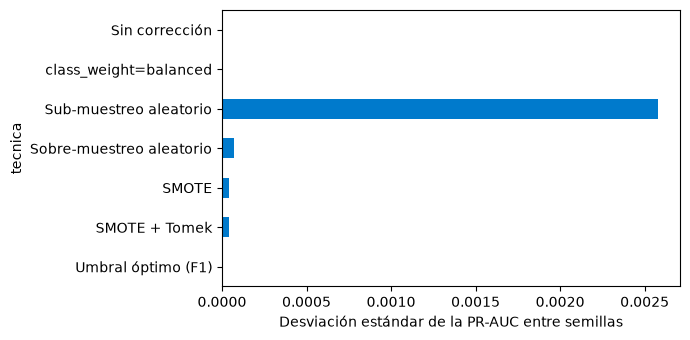

In [5]:
variacion = df.groupby('tecnica')['pr_auc'].std().loc[TECNICAS].round(5)
fig, ax = plt.subplots(figsize=(7, 3.5))
variacion[::-1].plot.barh(ax=ax, color='#007ACC')
ax.set_xlabel('Desviación estándar de la PR-AUC entre semillas')
plt.tight_layout()
variacion

**Respuesta.** Las técnicas **sin componente aleatorio** (`Sin corrección`, `class_weight=balanced`, y el ajuste de umbral, que usa una validación cruzada sin barajar) dan **exactamente el mismo resultado** con cualquier semilla: su desviación es 0. En ellas la semilla es un parámetro inofensivo, pero igual conviene registrarla.

Las técnicas de **remuestreo** sí dependen de la semilla, pero **en muy distinto grado**: el **sub-muestreo** es claramente el más variable (desviación de la PR-AUC ≈ 0.003, y de ≈ 0.03 en el *recall*), porque descarta ≈ 99 % de las filas negativas y cada semilla conserva un subconjunto distinto. El sobre-muestreo, SMOTE y SMOTE + Tomek casi no se mueven (desviaciones ≈ 0.0001 en PR-AUC): con un modelo lineal estable, duplicar o interpolar los 100 positivos produce prácticamente la misma frontera.

La conclusión práctica: para comparar técnicas con aleatoriedad hay que **repetir con varias semillas y reportar media y desviación**, no una sola corrida; y para hacerlo en MLflow, basta con una columna `semilla` y un `groupby`.

<h2 style="color: #007ACC;">Ejercicio 2. Otro modelo</h2>

Añadimos `'Random Forest'` como técnica sin tocar `construir`: una función envoltura reconoce la nueva etiqueta y delega en `construir` para las demás. El parámetro `modelo` ya es un argumento de `registrar_corrida`.

In [6]:
def construir_con_rf(tecnica, semilla=0):
    if tecnica == 'Random Forest':
        return RandomForestClassifier(300, min_samples_leaf=3, n_jobs=-1, random_state=semilla)
    if tecnica == 'Random Forest (balanced_subsample)':
        return RandomForestClassifier(300, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=semilla)
    return construir(tecnica, semilla)

mlflow.set_experiment('sol-ej2-otro-modelo');
for t in ['Sin corrección', 'class_weight=balanced', 'SMOTE']:
    registrar_corrida(t, constructor=construir_con_rf, modelo='regresion_logistica')
for t in ['Random Forest', 'Random Forest (balanced_subsample)']:
    registrar_corrida(t, constructor=construir_con_rf, modelo='random_forest')

tabla('sol-ej2-otro-modelo').sort_values('pr_auc', ascending=False).round(3)

,modelo,tecnica,semilla,recall,precision,f1,pr_auc
0,random_forest,Random Forest (balanced_subsample),0,0.42,0.913,0.575,0.686
1,random_forest,Random Forest,0,0.20,0.952,0.331,0.682
2,regresion_logistica,SMOTE,0,0.91,0.061,0.115,0.057
3,regresion_logistica,class_weight=balanced,0,0.93,0.060,0.113,0.057
4,regresion_logistica,Sin corrección,0,0.00,0.000,0.000,0.054


**Respuesta.** Fíjate en que el bosque tiene una PR-AUC mayor que *todas* las variantes de la regresión logística, y que sus métricas a umbral 0.5 son muy distintas: poco *recall* con precisión alta (un bosque sin pesos casi nunca cruza 0.5 cuando hay 1 % de positivos), y el efecto de `balanced_subsample` es subir el *recall*. La diferencia de PR-AUC (≈ 0.68 frente a ≈ 0.06) no se debe a ninguna técnica sino a la **capacidad**: los datos tienen dos clusters por clase y la frontera no es lineal, así que la regresión logística no puede ordenar bien los casos y el bosque sí. Es lo que anticipaba el cuaderno 12: en el modelo lineal las técnicas casi solo mueven el umbral, mientras que los modelos con más capacidad cambian además el ranking. Con la columna `modelo` registrada, la comparación entre familias se hace con un solo `groupby`.

<h2 style="color: #007ACC;">Ejercicio 3. Otros artefactos</h2>

In [7]:
mlflow.set_experiment('sol-ej3-artefactos');
for t in TECNICAS:
    registrar_corrida(t, figuras=('pr', 'roc', 'confusion'))

ultimo = mlflow.search_runs(experiment_names=['sol-ej3-artefactos'], max_results=1).loc[0, 'run_id']
print([a.path for a in mlflow.MlflowClient().list_artifacts(ultimo)])

['curva_pr.png', 'curva_roc.png', 'matriz_confusion.png']


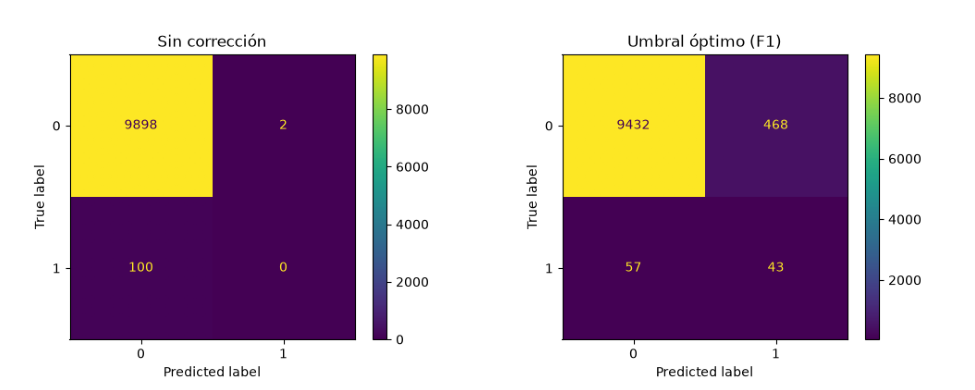

In [8]:
# Comparamos dos técnicas: la matriz de confusión del modelo sin corrección y la del ajuste de umbral
import matplotlib.image as mpimg, os

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for ax, t in zip(ejes, ['Sin corrección', 'Umbral óptimo (F1)']):
    rid = mlflow.search_runs(experiment_names=['sol-ej3-artefactos'], filter_string=f"params.tecnica = '{t}'").loc[0, 'run_id']
    ruta = mlflow.artifacts.download_artifacts(run_id=rid, artifact_path='matriz_confusion.png')
    ax.imshow(mpimg.imread(ruta)); ax.axis('off')
plt.tight_layout()

**Respuesta.** La curva ROC es casi idéntica entre las siete técnicas (mismo ranking), mientras que las matrices de confusión son muy distintas: sin corrección, la columna "predicho positivo" está vacía; con pesos o remuestreo se llena a costa de muchos falsos positivos; y con el umbral óptimo hay un punto intermedio. Es exactamente el diagnóstico **"ordena bien, decide mal"**: la ROC mide el ranking, la matriz mide la decisión a un umbral concreto. Tener ambos artefactos en cada corrida permite comprobarlo sin volver a entrenar.

<h2 style="color: #007ACC;">Ejercicio 4. Menos prevalencia</h2>

In [9]:
# Experimento original (cuaderno 13) con prevalencia 1 %
mlflow.set_experiment('desbalanceo-regresion-logistica');
for t in TECNICAS:
    registrar_corrida(t)

# Experimento nuevo con prevalencia 0.5 %
datos05 = partir(0.005)
print('Positivos en entrenamiento al 0.5 %:', datos05[4].sum())
mlflow.set_experiment('desbalanceo-prev-0.5pct');
for t in TECNICAS:
    registrar_corrida(t, datos=datos05)

Positivos en entrenamiento al 0.5 %: 50


In [10]:
a = tabla('desbalanceo-regresion-logistica').set_index('tecnica').loc[TECNICAS]
b = tabla('desbalanceo-prev-0.5pct').set_index('tecnica').loc[TECNICAS]
comparacion = pd.concat({'prev 1 %': a[['recall', 'precision', 'f1', 'pr_auc']], 'prev 0.5 %': b[['recall', 'precision', 'f1', 'pr_auc']]}, axis=1).round(3)
comparacion

prev 1 %                         prev 0.5 %  \
                           recall precision     f1 pr_auc     recall   
tecnica                                                                
Sin corrección               0.00     0.000  0.000  0.054       0.00   
class_weight=balanced        0.93     0.060  0.113  0.057       0.92   
Sub-muestreo aleatorio       0.92     0.061  0.115  0.058       0.92   
Sobre-muestreo aleatorio     0.93     0.060  0.113  0.057       0.90   
SMOTE                        0.91     0.061  0.115  0.057       0.90   
SMOTE + Tomek                0.91     0.061  0.115  0.057       0.90   
Umbral óptimo (F1)           0.43     0.084  0.141  0.054       0.04   

                                                  
                         precision     f1 pr_auc  
tecnica                                           
Sin corrección               0.000  0.000  0.039  
class_weight=balanced        0.031  0.060  0.030  
Sub-muestreo aleatorio       0.027  0.052  0.027  
Sobre-muestreo aleatorio     0.031  0.059  0.030  
SMOTE                        0.033  0.065  0.030  
SMOTE + Tomek                0.033  0.065  0.030  
Umbral óptimo (F1)           0.028  0.033  0.039

**Respuesta.** Al bajar la prevalencia a la mitad (50 positivos de entrenamiento en lugar de 100), la **precisión** y la **PR-AUC** caen en todas las técnicas: con menos positivos hay menos señal para aprender y, además, la precisión depende de la prevalencia (cuaderno 12). El *recall* se mantiene alto (≈ 0.9) en las técnicas que corrigen, pero a costa de más falsos positivos. El caso extremo es el **ajuste de umbral**: con 50 positivos, el umbral que maximiza el $F_1$ en la validación interna deja de generalizar y su *recall* en prueba cae a ≈ 0.04 (frente a 0.43 con 100 positivos). Con tan pocos eventos, el umbral óptimo es él mismo muy ruidoso. Observa que esta comparación entre experimentos se hizo **solo con `search_runs`**, sin volver a entrenar nada: esa es la ventaja de tener los resultados registrados.

<h2 style="color: #007ACC;">Ejercicio 5. Romper la reproducibilidad</h2>

Registramos dos técnicas con `semilla=7` **sin** guardar la semilla (`registrar_semilla=False`). Luego intentamos reconstruirlas como en la sección 8 del cuaderno 13.

In [11]:
mlflow.set_experiment('sol-ej5-sin-semilla');
for t in ['Sin corrección', 'SMOTE']:
    registrar_corrida(t, semilla=7, registrar_semilla=False)

df = mlflow.search_runs(experiment_names=['sol-ej5-sin-semilla'])
for t in ['Sin corrección', 'SMOTE']:
    corrida = mlflow.get_run(df.loc[df['params.tecnica'] == t, 'run_id'].iloc[0])
    p = corrida.data.params
    print(f'{t}: parámetros guardados = {sorted(p)}')
    try:
        semilla = int(p['semilla'])                  # como en la sección 8 original
    except KeyError:
        print('   -> KeyError: no hay semilla registrada. Probamos con la semilla por defecto (0):')
        semilla = 0
    nuevo = evaluar(construir(t, semilla).fit(X_tr, y_tr), X_te, y_te)
    print('   ¿coincide el pr_auc?', np.isclose(nuevo['pr_auc'], corrida.data.metrics['pr_auc']),
          f"(registrado {corrida.data.metrics['pr_auc']:.5f} vs reproducido {nuevo['pr_auc']:.5f})")

Sin corrección: parámetros guardados = ['modelo', 'n_pos_train', 'n_train', 'prevalencia', 'tecnica']
   -> KeyError: no hay semilla registrada. Probamos con la semilla por defecto (0):
   ¿coincide el pr_auc? True (registrado 0.05406 vs reproducido 0.05406)
SMOTE: parámetros guardados = ['modelo', 'n_pos_train', 'n_train', 'prevalencia', 'tecnica']
   -> KeyError: no hay semilla registrada. Probamos con la semilla por defecto (0):
   ¿coincide el pr_auc? False (registrado 0.05662 vs reproducido 0.05690)


**Respuesta.** Sin la semilla, la sección 8 falla con `KeyError` en cuanto la buscamos. Si "arreglamos" el código usando una semilla por defecto, el resultado depende de la técnica:

- **`Sin corrección`** *parece* reproducirse: no tiene ningún componente aleatorio, así que la semilla no importa. Es un falso consuelo: el éxito depende de una propiedad del modelo que nadie dejó escrita.
- **`SMOTE`** **no** se reproduce: los puntos sintéticos dependen de la semilla (se usó 7 y reconstruimos con 0), y nadie puede saber cuál era.

Moraleja: lo que no se registra no se puede reproducir, y a veces *parece* que sí, hasta que cambia el modelo.

<h2 style="color: #007ACC;">Ejercicio 6. Reflexión: elegir con validación y registrar la prueba una vez</h2>

Cambios en `registrar_corrida`:

1. **Partir el entrenamiento** en entrenamiento y validación (o usar validación cruzada) y registrar las métricas con el prefijo `val_`. Las corridas de comparación **no tocan** la prueba.
2. **Elegir** con `search_runs` ordenando por una métrica de validación (aquí, `val_pr_auc`).
3. **Reentrenar** la configuración elegida con todo el entrenamiento y registrar **una única corrida final**, etiquetada `etapa=final`, con las métricas `test_*`. La prueba se evalúa una vez.

In [12]:
X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=.3, stratify=y_tr, random_state=0)

mlflow.set_experiment('sol-ej6-seleccion');
for t in TECNICAS:                                  # 1. comparar SOLO con validación
    with mlflow.start_run(run_name=t):
        mlflow.log_params({'tecnica': t, 'semilla': 0, 'esquema': 'train/val 70/30'})
        mlflow.log_metrics({f'val_{k}': v for k, v in evaluar(construir(t, 0).fit(X_fit, y_fit), X_val, y_val).items()})

df = mlflow.search_runs(experiment_names=['sol-ej6-seleccion'], order_by=['metrics.val_pr_auc DESC'])
mejor = df.loc[0, 'params.tecnica']                 # 2. elegir con validación
print(df[['params.tecnica', 'metrics.val_pr_auc', 'metrics.val_f1']].round(3).to_string(index=False))
print('\nTécnica elegida:', mejor)

with mlflow.start_run(run_name=f'FINAL · {mejor}'):  # 3. la prueba se evalúa una sola vez
    mlflow.set_tag('etapa', 'final')
    mlflow.log_params({'tecnica': mejor, 'semilla': 0, 'esquema': 'reentrenado con todo el entrenamiento'})
    final = construir(mejor, 0).fit(X_tr, y_tr)
    mlflow.log_metrics({f'test_{k}': v for k, v in evaluar(final, X_te, y_te).items()})

          params.tecnica  metrics.val_pr_auc  metrics.val_f1
Sobre-muestreo aleatorio               0.061           0.119
   class_weight=balanced               0.060           0.117
           SMOTE + Tomek               0.059           0.122
                   SMOTE               0.059           0.122
  Sub-muestreo aleatorio               0.057           0.106
      Umbral óptimo (F1)               0.055           0.103
          Sin corrección               0.055           0.000

Técnica elegida: Sobre-muestreo aleatorio


Resultado: en el experimento hay **7 corridas con métricas de validación y una sola con métricas de prueba** (la etiquetada `final`). Si alguien abre la interfaz y ve métricas `test_*` en las 7 corridas, sabe que la elección se hizo mirando la prueba.